# Logistic Regression Deep Dive


**R dependencies:** `tidyverse`, `EGAnet`, `DescTools`, `car`, `ggplot2`, `GGally`, `margins`, and `caret`. Install any missing packages before running.

# Load packages

In [1]:
# Load packages
library(tidyverse); library(EGAnet)
library(DescTools); library(car)
library(ggplot2); library(GGally)
library(margins); library(caret)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

EGAnet (version 2.4.1) 

For help getting started, see <https://r-ega.net> 

For bugs and errors, submit an issue to <https://github.com/hfgolino/EGAnet/issues>

Loading required package: carData


Attaching package: ‘car’


The following object is masked from ‘package:DescTools’:

    Recode


The following object is masked from ‘package:dplyr’:

    recode


The following object is masked from ‘package:purrr’:

    some


Loading required package: lattice


Attaching p

## Motivating Dataset 1: WNBA

Research question: Are there stats that predict the number of games a **young** player will start?

That's a regression problem. Alternatively, looking into players' statistics we can also attempt to predict: 

> *Whether a player is a regular starter or not*

:::{.callout-tip}

## Load the data.

Data scraped from [wehoop](https://wehoop.sportsdataverse.org/)

:::

In [2]:
wnba <- read.csv("./data/wnba_player-stats_2024-2025.csv")

In [3]:
head(wnba)

,game_id,season,season_type,game_date,game_date_time,athlete_id,athlete_display_name,team_id,team_name,team_location,⋯,opponent_team_name,opponent_team_location,opponent_team_display_name,opponent_team_abbreviation,opponent_team_logo,opponent_team_color,opponent_team_alternate_color,opponent_team_score,age,years
,<int>,<int>,<int>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>
1,401820317,2025,3,2025-09-16,2025-09-17T01:30:00Z,4398776,NaLyssa Smith,17,Aces,Las Vegas,⋯,Storm,Seattle,Seattle Storm,SEA,https://a.espncdn.com/i/teamlogos/wnba/500/sea.png,2c5235,fee11a,86,25,3
2,401820317,2025,3,2025-09-16,2025-09-17T01:30:00Z,4433633,Kierstan Bell,17,Aces,Las Vegas,⋯,Storm,Seattle,Seattle Storm,SEA,https://a.espncdn.com/i/teamlogos/wnba/500/sea.png,2c5235,fee11a,86,25,3
3,401820317,2025,3,2025-09-16,2025-09-17T01:30:00Z,3149391,A'ja Wilson,17,Aces,Las Vegas,⋯,Storm,Seattle,Seattle Storm,SEA,https://a.espncdn.com/i/teamlogos/wnba/500/sea.png,2c5235,fee11a,86,29,7
4,401820317,2025,3,2025-09-16,2025-09-17T01:30:00Z,2529122,Chelsea Gray,17,Aces,Las Vegas,⋯,Storm,Seattle,Seattle Storm,SEA,https://a.espncdn.com/i/teamlogos/wnba/500/sea.png,2c5235,fee11a,86,32,10
5,401820317,2025,3,2025-09-16,2025-09-17T01:30:00Z,4065870,Jackie Young,17,Aces,Las Vegas,⋯,Storm,Seattle,Seattle Storm,SEA,https://a.espncdn.com/i/teamlogos/wnba/500/sea.png,2c5235,fee11a,86,28,6
6,401820317,2025,3,2025-09-16,2025-09-17T01:30:00Z,2529458,Cheyenne Parker-Tyus,17,Aces,Las Vegas,⋯,Storm,Seattle,Seattle Storm,SEA,https://a.espncdn.com/i/teamlogos/wnba/500/sea.png,2c5235,fee11a,86,33,10


:::{.callout-tip}

## See the data.

Just printing the first few rows of the dataframe using `head()` will not properly display all the columns as there are too many. 

Instead, let's print a summary of the dataframe's structure and metadata using `str()`

:::

In [4]:
str(wnba)

'data.frame':	6716 obs. of  59 variables:
 $ game_id                          : int  401820317 401820317 401820317 401820317 401820317 401820317 401820317 401820317 401820317 401820317 ...
 $ season                           : int  2025 2025 2025 2025 2025 2025 2025 2025 2025 2025 ...
 $ season_type                      : int  3 3 3 3 3 3 3 3 3 3 ...
 $ game_date                        : chr  "2025-09-16" "2025-09-16" "2025-09-16" "2025-09-16" ...
 $ game_date_time                   : chr  "2025-09-17T01:30:00Z" "2025-09-17T01:30:00Z" "2025-09-17T01:30:00Z" "2025-09-17T01:30:00Z" ...
 $ athlete_id                       : int  4398776 4433633 3149391 2529122 4065870 2529458 2987869 4281190 2590093 3934218 ...
 $ athlete_display_name             : chr  "NaLyssa Smith" "Kierstan Bell" "A'ja Wilson" "Chelsea Gray" ...
 $ team_id                          : int  17 17 17 17 17 17 17 17 17 17 ...
 $ team_name                        : chr  "Aces" "Aces" "Aces" "Aces" ...
 $ team_location      

:::{.callout-tip}

## Who are the players?

Let's check out the player names using a frequency table to identify potential duplicates: `table(wnba$athlete_display_name)`

:::

In [5]:
knitr::kable(
  as.data.frame(table(wnba$athlete_display_name)),
  col.names = c("Athlete", "Frequency"),
  caption = "Number of Observations per Athlete"
)



Table: Number of Observations per Athlete

|Athlete                  | Frequency|
|:------------------------|---------:|
|A'ja Wilson              |        45|
|Aaliyah Edwards          |        43|
|Aaliyah Nye              |        46|
|Aari McDonald            |        34|
|Aerial Powers            |        14|
|Ajae Petty               |         3|
|Alanna Smith             |        44|
|Alexis Prince            |         1|
|Alissa Pili              |        40|
|Aliyah Boston            |        48|
|Allisha Gray             |        45|
|Alysha Clark             |        45|
|Alyssa Thomas            |        46|
|Amy Okonkwo              |         8|
|Anastasiia Olairi Kosu   |        46|
|Aneesah Morrow           |        44|
|Angel Reese              |        45|
|Annika Soltau            |         1|
|Ariel Atkins             |        44|
|Arike Ogunbowale         |        36|
|Aziaha James             |        43|
|Azura Stevens            |        44|
|Breanna Stewart   

:::{.callout-tip}

## Collate game stats per player

Hold up... we have players listed multiple times...

These data are from box scores of *each* game that the players played. We need to get summaries of their statistics in order to answer our question.

:::

In [6]:
# Let's get summaries
wnba_summary <- wnba %>%
  group_by(athlete_id, athlete_display_name) %>%
  summarize(
    GS = sum(starter, na.rm = TRUE), # sum for total games started
    PTS = mean(points, na.rm = TRUE), # average points per game
    TRB = mean(rebounds, na.rm = TRUE), # average rebounds per game
    AST = mean(assists, na.rm = TRUE), # average assists per game
    STL = mean(steals, na.rm = TRUE), # average steals per game
    BLK = mean(blocks, na.rm = TRUE), # average blocks per game
    TOV = mean(turnovers, na.rm = TRUE), # average turnovers per game
    Age = unique(age) # age at start of season
  )

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by athlete_id and athlete_display_name.
ℹ Output is grouped by athlete_id.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(athlete_id, athlete_display_name))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.


In [7]:
head(wnba_summary)

athlete_id,athlete_display_name,GS,PTS,TRB,AST,STL,BLK,TOV,Age
<int>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
869,DeWanna Bonner,4,9.911765,4.1764706,1.117647,0.9117647,0.2647059,0.8529412,38
887,Sami Whitcomb,20,9.000000,2.6363636,2.500000,0.7954545,0.1818182,1.5227273,37
918,Tina Charles,42,16.279070,5.7674419,1.720930,0.7674419,0.4418605,1.9069767,36
924,Alysha Clark,15,3.880952,2.7857143,1.214286,0.6190476,0.0952381,0.5238095,38
981,Courtney Vandersloot,7,10.571429,3.1428571,5.285714,1.5714286,0.2857143,2.4285714,36
1004,Sydney Colson,6,2.387097,0.8387097,2.064516,0.5161290,0.1935484,1.1935484,36


:::{.callout-tip}

## Define young.

OK. Now that we're set up with our variables of interest, let's tackle what "young" means with respect to our research question.

:::

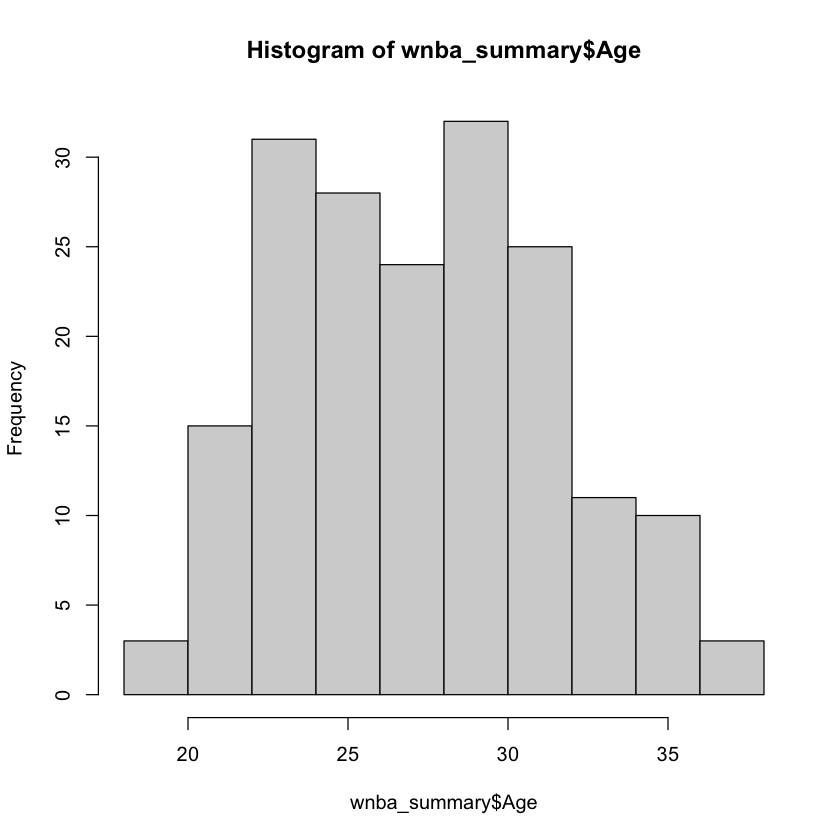

In [8]:
hist(wnba_summary$Age, breaks = "FD")

:::{.callout-tip}

## A more specific definition.

A histogram helps a little bit but we might want to be more objective. Let's classify *young* as the 25th percentile of the age of people in the WNBA.

:::

In [9]:
quantile(wnba_summary$Age, probs = 0.25, na.rm = TRUE)

25% 
 24

:::{.callout-important}

## Your turn.

Subset the `Age` to be ages less than or equal to the 25th percentile and store in an object called `young_wnba`.

:::

In [10]:
young_wnba <- wnba_summary[
  wnba_summary$Age <= 
  quantile(wnba_summary$Age, probs = 0.25, na.rm = TRUE),
]

:::{.callout-important}

## Your turn.

Check out the frequencies of games started using `table`.

:::

In [11]:
# table(young_wnba$GS)

knitr::kable(
  as.data.frame(table(young_wnba$GS)),
  col.names = c("Games Started", "Frequency"),
  caption = "Distribution of Games Started for Young Players"
)



Table: Distribution of Games Started for Young Players

|Games Started | Frequency|
|:-------------|---------:|
|0             |        24|
|1             |         3|
|2             |         1|
|6             |         1|
|8             |         2|
|11            |         1|
|12            |         1|
|13            |         2|
|15            |         2|
|16            |         1|
|23            |         1|
|25            |         1|
|30            |         1|
|34            |         1|
|37            |         2|
|39            |         1|
|41            |         1|
|44            |         2|
|48            |         1|

:::{.callout-tip}

## A Linear Model.

Now, let's fit a linear regression model predicting games started (`GS`) using the following data:
- points (`PTS`)
- total rebounds (`TRB`)
- assists (`AST`)
- steals (`STL`)
- blocks (`BLK`)
- turnovers (`TOV`)

:::

In [12]:
summary(gs_lm <- lm(GS ~ PTS + TRB + AST + STL + BLK + TOV, data = young_wnba))


Call:
lm(formula = GS ~ PTS + TRB + AST + STL + BLK + TOV, data = young_wnba)

Residuals:
     Min       1Q   Median       3Q      Max 
-17.9927  -4.1092   0.0983   3.8261  25.7868 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  -3.5970     1.9328  -1.861   0.0698 .  
PTS           3.4532     0.5295   6.522 7.04e-08 ***
TRB           1.0636     0.8486   1.253   0.2170    
AST          -1.0172     1.6938  -0.601   0.5513    
STL          -1.7003     4.3448  -0.391   0.6975    
BLK          -6.4410     4.4587  -1.445   0.1560    
TOV          -4.2068     2.8357  -1.483   0.1454    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 7.648 on 42 degrees of freedom
  (3 observations deleted due to missingness)
Multiple R-squared:  0.7807,	Adjusted R-squared:  0.7494 
F-statistic: 24.92 on 6 and 42 DF,  p-value: 2.295e-12


:::{.callout-important}

## Your turn.

Interpret the `AST` estimate (remember, we're using *average per game* statistics)

> Answer:

*Write your response here.*

:::

:::{.callout-tip}

## A Binarized Outcome.

Let's shift over to a **binary classification problem** that looks into player stats and classifies them as a potential starter or not. 

To be regarded as a potential starter, a young player needs to have started *at least* $1$ game. Our response will be a binarized version of `games_started`.

We will convert games started (`GS`) into `0` and `1`, where:
- games started > 0 is `1`
- games started equal to 0 is `0`. 

Store it in a variable called `starter` in `young_wnba`.

:::

> The `ifelse()` approach checks every row one by one for the test condition and manually assigns a $1$ or a $0$.

In [13]:
young_wnba$starter <- ifelse(young_wnba$GS > 0, 1, 0)

> The `as.numeric()` approach evaluates `young_wnba$GS > 0` to create a logical vector (`TRUE` or `FALSE`), then uses R's built-in rule that `TRUE` is encoded as $1$ and `FALSE` equals $0$.

In [14]:
young_wnba$starter <- as.numeric(young_wnba$GS > 0)

:::{.callout-tip}

## Are the two classes balanced?

Let's see if our new variable, `starter`, is balanced (use `table`). This is important when training a good model. If our dataset is heavily imbalanced towards examples from one class the model can overfit to it.<br>
<br>

> Model might not learn a good prediction function factoring in the explanatory variables and instead may just memorize predicting the majority class. You will still get a high accuracy in this manner just because most of the examples belong to one class but the model has little predictive value. 
>
> Think of a classifier that wants to detect credit card fraud. Most transactions are *non-fradulent (0)*. A model that never predicts *fraud* can be accurate most of the times but the consequence of failure is serious and substantial. 

:::

In [15]:
table(young_wnba$starter)


 0  1 
24 25 

:::{.callout-tip}

## A linear binary model.

Before doing logistic regression, let's see what happens with linear regression.

:::

In [16]:
summary(start_lm <- lm(starter ~ PTS + TRB + AST + STL + BLK + TOV, data = young_wnba))


Call:
lm(formula = starter ~ PTS + TRB + AST + STL + BLK + TOV, data = young_wnba)

Residuals:
    Min      1Q  Median      3Q     Max 
-0.5674 -0.2400 -0.1381  0.3508  0.7936 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)  
(Intercept)  0.06140    0.09723   0.631   0.5312  
PTS          0.06525    0.02663   2.450   0.0185 *
TRB         -0.02442    0.04269  -0.572   0.5703  
AST         -0.05453    0.08520  -0.640   0.5256  
STL          0.20547    0.21856   0.940   0.3525  
BLK         -0.04276    0.22429  -0.191   0.8497  
TOV          0.09512    0.14265   0.667   0.5085  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.3847 on 42 degrees of freedom
  (3 observations deleted due to missingness)
Multiple R-squared:  0.4923,	Adjusted R-squared:  0.4198 
F-statistic: 6.788 on 6 and 42 DF,  p-value: 4.422e-05


:::{.callout-important}

## Your turn

Comment on the differences between this model and our previous model (using `GS`)

> Answer:

*Write your response here.*

:::

> Let's plot our predicted values

Warning message:
“Removed 3 rows containing non-finite outside the scale range (`stat_smooth()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_point()`).”


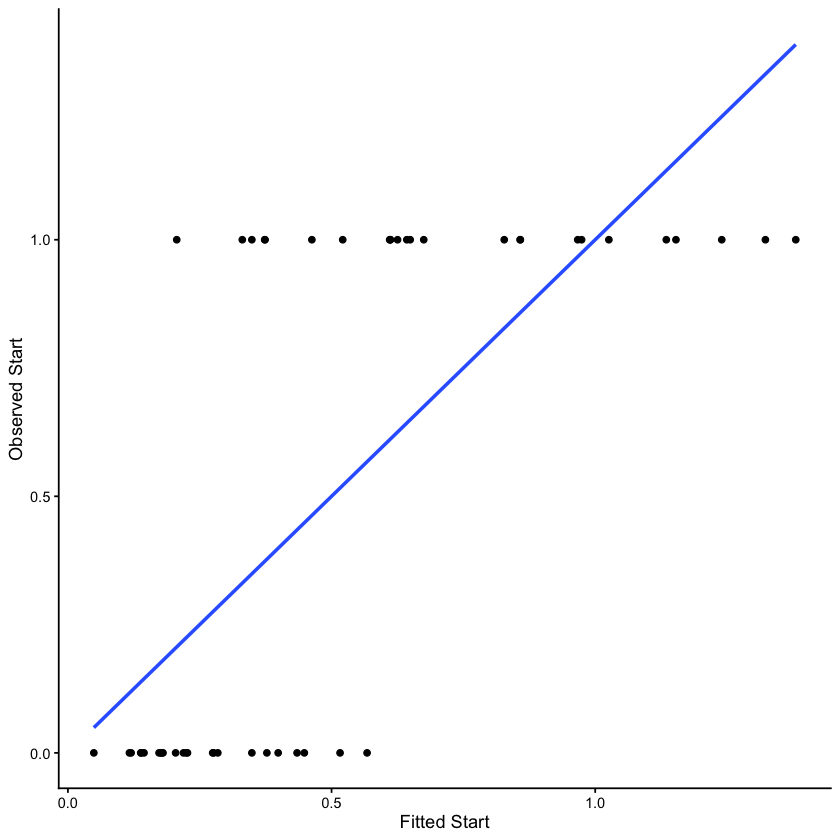

In [17]:
# Create a new vector
start_fitted <- numeric(length = nrow(young_wnba))

# Identify missing observations
missing_start <- is.na(young_wnba$starter)

# Populate start fitted vector
start_fitted[missing_start] <- NA
start_fitted[!missing_start] <- start_lm$fitted.values
  
# Add fitted values
young_wnba$start_fitted <- start_fitted

# Plot
young_wnba %>%
ggplot(aes(x = start_fitted, y = young_wnba$starter)) +
  geom_point() +
  geom_smooth(formula = "y ~ x", method = "lm", se = FALSE) +
  labs(x = "Fitted Start", y = "Observed Start") +
  theme_classic()
# Demonstration of what NOT to do!

:::{.callout-tip}

## A logisitc model.

Let's try logistic regression now. 

Notice the use of `glm` -- *a family of models*. The family parameter in R's `glm()` function specifies the error distribution (**random component**) and the **link function** that connect a combination of your linear predictors to the expected value of your response variable.

- By default, it is set to `gaussian`, the distribution in case of standard linear regression, which is also the state of this model by default.
- Here we need to set the model parameter value to `binomial`, which is the appropraite choice for binary outcomes or proportions. 
    - R uses `binomial` instead of *bernoulli* because the Bernoulli distribution is just a special case of the Binomial distribution where the number of trials ($n$) equals 1.
:::

In [18]:
# Logistic regression
start_logm <- glm(
  starter ~ PTS + AST + STL + BLK + TOV, 
  data = young_wnba, 
  family = binomial(link = "logit")
  # do not forget to change 'family'!
  # by default, linear regression is performed
  # unless you change 'family'
)

# Summarize to get parameters
summary(start_logm)


Call:
glm(formula = starter ~ PTS + AST + STL + BLK + TOV, family = binomial(link = "logit"), 
    data = young_wnba)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)   
(Intercept)  -3.9088     1.1981  -3.263   0.0011 **
PTS           0.4466     0.3486   1.281   0.2002   
AST           0.3141     0.8702   0.361   0.7181   
STL           0.7958     2.9656   0.268   0.7884   
BLK          -1.7235     2.0541  -0.839   0.4014   
TOV           1.6516     1.5956   1.035   0.3006   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 67.908  on 48  degrees of freedom
Residual deviance: 30.905  on 43  degrees of freedom
  (3 observations deleted due to missingness)
AIC: 42.905

Number of Fisher Scoring iterations: 6


:::{.callout-note}

## Takeaways from the summary report.

<span style="color:#1565C0;">Unlike linear regression, we are actually **not** going to use the metrics specified in this report to evaluate the fit or performance of our logistic regression model.</span>

We are however, going to check the estimates of our model coefficients and their $p$-values to understand the contributions of our predictors.

:::

:::{.callout-tip}

## Interpreting model coefficients.

These parameter estimates are tricky. They are in the *log-odds* scale and interpreting them as is can give us a headache! 🙃

Instead, we can convert them to odds ratios $\rightarrow$ *change in odds of success for unit change in predictor*. Remember,

$$\begin{aligned}
\frac{\omega_{after}}{\omega_{before}} = e^{\beta}\\
\omega_{after} = e^{\beta}\omega_{before}
\end{aligned}$$

:::

In [19]:
# Get coefficients and convert them to odds ratios
knitr::kable(
  as.data.frame(exp(coef(start_logm))),
  col.names = c("Parameter", "Odds Ratio"),
  caption = "Regression model coefficients in odds scale"
)



Table: Regression model coefficients in odds scale

|Parameter   | Odds Ratio|
|:-----------|----------:|
|(Intercept) |  0.0200639|
|PTS         |  1.5629776|
|AST         |  1.3689946|
|STL         |  2.2161601|
|BLK         |  0.1784323|
|TOV         |  5.2152828|

:::{.callout-tip}

## How to interpret `AST`?

<span style="color:#1565C0;">For each additional assist per game, the odds of having started a game are multiplied by the estimated odds ratio for `AST`, holding the other predictors fixed.</span>

If the estimated odds ratio is 0.724, this corresponds to 27.6% lower odds (not 27.6 percentage points lower probability) for unit change in assists per game, other predictors held constant. 

<span style="color:#1565C0;">**Note**</span>, The value 0.724 is *simply illustrative* here; use the estimate from your fitted model for an accurate interpretation in this case.

:::

:::{.callout-important}

Interpret your model parameters in a similar manner.
:::

*Enter response here*

- `PTS`:
- `AST`:
- `STL`:
- `BLK`:
- `TOV`:

:::{.callout-note}

## A note on statistical significance.

An important observation is that **none of the five predictors is individually statistically significant at the $5\%$ level**.

Consequently, we do not have sufficient statistical evidence to conclude that any individual predictor has a nonzero association with starting status after controlling for the other predictors.

This **does not** establish that these variables have no relationship with starting status. Simply that given this data, we cannot weed out the uncertainty around their estimated impacts.

:::

<!---
Flip the OR for a more intuitive interpretation
1 / OR
--->

<!--- Back to the slides --->

:::{.callout-tip}

## McFadden's R-squared.

We can also obtain a pseudo-$R^2$, which is a goodness-of-fit measure used for discrete choice and logistic regression models. It's not truly an $R^2$ measure like we talked about in linear regression. It will be an approximation intended to be *like* $R^2$.

A higher McFadden's $R^2$ indicates a better relative fit.
:::

In [20]:
# McFadden's R-squared
PseudoR2(start_logm)

McFadden 
0.5448968

:::{.callout-tip}

## Marginal effects of predictors.

Another convenient function comes from the `margins` package. It produces the marginal effects of predictors in the original scale of the data, probabilities in this case.

:::

In [21]:
summary(margins(start_logm))

,factor,AME,SE,z,p,lower,upper
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,AST,0.03080621,0.08500002,0.3624259,0.7170338,-0.13579078,0.1974032
2,BLK,-0.16905402,0.19649099,-0.8603652,0.3895877,-0.55416928,0.2160612
3,PTS,0.04380405,0.03161753,1.3854354,0.1659194,-0.01816518,0.1057733
4,STL,0.07805370,0.29040084,0.2687792,0.7880996,-0.49112149,0.6472289
5,TOV,0.16199655,0.15065706,1.0752669,0.2822552,-0.13328586,0.4572790


:::{.callout-note}

## Takeaways from this summary report

- The Average Marginal Effects (AMEs) represent the average change in the predicted probability of being a starter for a one-unit increase in each predictor, holding other predictors at their observed values.

- None of these marginal effects is statistically significant at the $5\%$ level (all p-values exceed $0.05$, and all confidence intervals include zero).

:::

:::{.callout-important}

## Why is the marginal effect of each predictor on the probability scale presented here as an average estimate?

*Enter your response here...*

:::

:::{.callout-tip}

## Multicollinearity.

We need to check for multicollinear variables using the previously used `car` package.

:::

In [22]:
# Print out the VIF table
knitr::kable(
  as.data.frame(vif(start_logm)),
  col.names = c("Parameter", "VIF score"),
  caption = "VIF table"
)



Table: VIF table

|Parameter | VIF score|
|:---------|---------:|
|PTS       |  3.035550|
|AST       |  2.347744|
|STL       |  2.862729|
|BLK       |  1.850014|
|TOV       |  2.036263|

:::{.callout-tip}

## Model evaluation

As a final model evaluation step, we can see how well our model predicts our outcome. You'll need to install the `caret` package for this. We will:

- set a probability threshold to convert probabilities to class labels. 
$$\begin{aligned}
Y &= 1; P(Y=1 \mid X)> \alpha\\
Y &= 0; \text{otherwise}
\end{aligned}$$

- generate a confusion matrix and identify precision and recall
- print the F1-score: *harmonic mean of precision and recall*

:::

In [23]:
# First, we need to get predictions out from our model
predictions <- predict(start_logm, type = "response")
# We need `type = "response"` to get probabilities out

# Afterward, we can convert the probabilities to classes
classes <- ifelse(predictions > 0.50, 1, 0)

# Actual outcomes for the observations used in the model
actual <- model.response(model.frame(start_logm))

In [24]:
# You'll need to install the {caret} package (if you don't have it)
# Remember that our prediction is toward the class valued as `1`
# Higher probabilities mean a greater likelihood of belonging to `1`
# (according to our model)
# Compute the confusion matrix
cm <- confusionMatrix(
  data = factor(classes, levels = c(0, 1)),
  reference = factor(actual, levels = c(0, 1)),
  positive = "1"
)

# Print the confusion matrix and evaluation metrics
print(cm)

Confusion Matrix and Statistics

          Reference
Prediction  0  1
         0 20  5
         1  4 20
                                          
               Accuracy : 0.8163          
                 95% CI : (0.6798, 0.9124)
    No Information Rate : 0.5102          
    P-Value [Acc > NIR] : 8.726e-06       
                                          
                  Kappa : 0.6328          
                                          
 Mcnemar's Test P-Value : 1               
                                          
            Sensitivity : 0.8000          
            Specificity : 0.8333          
         Pos Pred Value : 0.8333          
         Neg Pred Value : 0.8000          
             Prevalence : 0.5102          
         Detection Rate : 0.4082          
   Detection Prevalence : 0.4898          
      Balanced Accuracy : 0.8167          
                                          
       'Positive' Class : 1               
                                    

In [25]:
# Extract and print the F1-score
cat("F1-score:", round(cm$byClass["F1"], 3), "\n")

F1-score: 0.816 


:::{.callout-important}

## List the precision, recall and F1-score of your model

*Enter response here...*

:::

:::{.callout-tip}

## Visualizing our predictions

We can also visualize our predictions using a mosaic plot.

:::

          actual
prediction  0  1
         0 20  5
         1  4 20

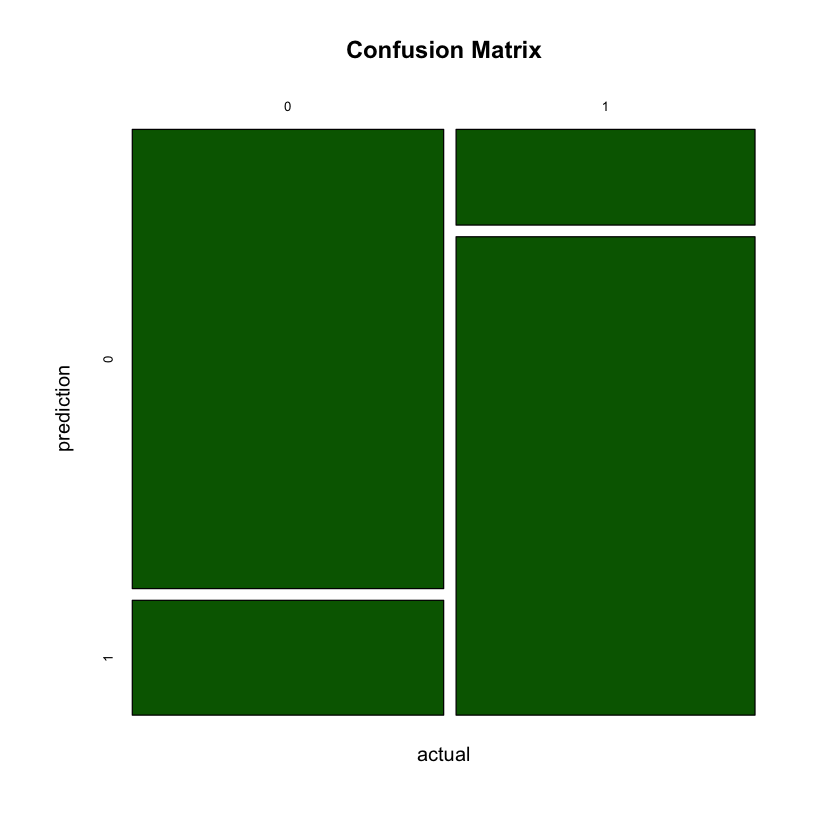

In [26]:
# First, we'll need to create a table of our prediction and actual
mosaic_table <- table(
  prediction = classes,
  actual = na.omit(young_wnba$starter)
)

# Print out the table
mosaic_table

# Next we can input this into the mosaicplot() function in base R
mosaicplot(
  mosaic_table, main = 'Confusion Matrix', 
  xlab = 'actual', ylab = 'prediction',
  color = 'darkgreen'
)